# Experiment 11: Credit Score Classification
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Write a program for the task of **Credit Score Classification** (Good / Standard / Poor).

## Note on the data
No internet data set is used here: a **synthetic customer data set** (same kind of columns as the popular Kaggle *Credit Score Classification* data) is generated with a fixed random seed, so the notebook runs anywhere. To use the real CSV, replace the data-loading cell with `df = pd.read_csv('train.csv')` and keep the column names.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)
n = 3000
df = pd.DataFrame({
    'Age': rng.integers(18, 65, n),
    'Annual_Income': rng.normal(55000, 20000, n).clip(10000, 150000).round(0),
    'Num_Bank_Accounts': rng.integers(1, 10, n),
    'Num_Credit_Cards': rng.integers(1, 10, n),
    'Interest_Rate': rng.integers(2, 30, n),
    'Num_Delayed_Payments': rng.integers(0, 25, n),
    'Credit_Utilization_Ratio': rng.uniform(20, 50, n).round(2),
    'Outstanding_Debt': rng.uniform(0, 5000, n).round(2),
    'Credit_History_Age': rng.integers(1, 30, n),
})
# hidden rule that produces a score, plus noise
score = (0.00004 * df.Annual_Income - 0.08 * df.Num_Delayed_Payments - 0.05 * df.Interest_Rate
         - 0.0004 * df.Outstanding_Debt - 0.03 * df.Credit_Utilization_Ratio
         + 0.05 * df.Credit_History_Age + rng.normal(0, 0.15, n))
df['Credit_Score'] = pd.qcut(score, [0, 0.25, 0.75, 1.0], labels=['Poor', 'Standard', 'Good'])
df.to_csv('credit_score_synthetic.csv', index=False)
print(df.shape)
print(df['Credit_Score'].value_counts())
df.head()

(3000, 10)
Credit_Score
Standard    1500
Poor         750
Good         750
Name: count, dtype: int64


,Age,Annual_Income,Num_Bank_Accounts,Num_Credit_Cards,Interest_Rate,Num_Delayed_Payments,Credit_Utilization_Ratio,Outstanding_Debt,Credit_History_Age,Credit_Score
0,22,74259.0,6,9,29,9,32.92,3695.91,17,Standard
1,54,40508.0,6,8,26,15,25.23,2110.92,20,Standard
2,48,37925.0,9,3,28,6,44.94,716.91,3,Poor
3,38,64194.0,7,5,3,8,29.74,1933.47,5,Good
4,38,74771.0,2,8,20,8,48.03,4355.24,2,Standard


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X = df.drop(columns='Credit_Score')
y = df['Credit_Score'].astype(str)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train, y_train)
rf_pred = rf.predict(X_test)

sc = StandardScaler().fit(X_train)
lr = LogisticRegression(max_iter=2000).fit(sc.transform(X_train), y_train)
lr_pred = lr.predict(sc.transform(X_test))

print('Random Forest accuracy      :', round(accuracy_score(y_test, rf_pred), 4))
print('Logistic Regression accuracy:', round(accuracy_score(y_test, lr_pred), 4))
print('\nRandom Forest - classification report')
print(classification_report(y_test, rf_pred))

Random Forest accuracy      : 0.8583
Logistic Regression accuracy: 0.935

Random Forest - classification report
              precision    recall  f1-score   support

        Good       0.91      0.79      0.85       150
        Poor       0.97      0.74      0.84       150
    Standard       0.80      0.95      0.87       300

    accuracy                           0.86       600
   macro avg       0.90      0.83      0.85       600
weighted avg       0.87      0.86      0.86       600



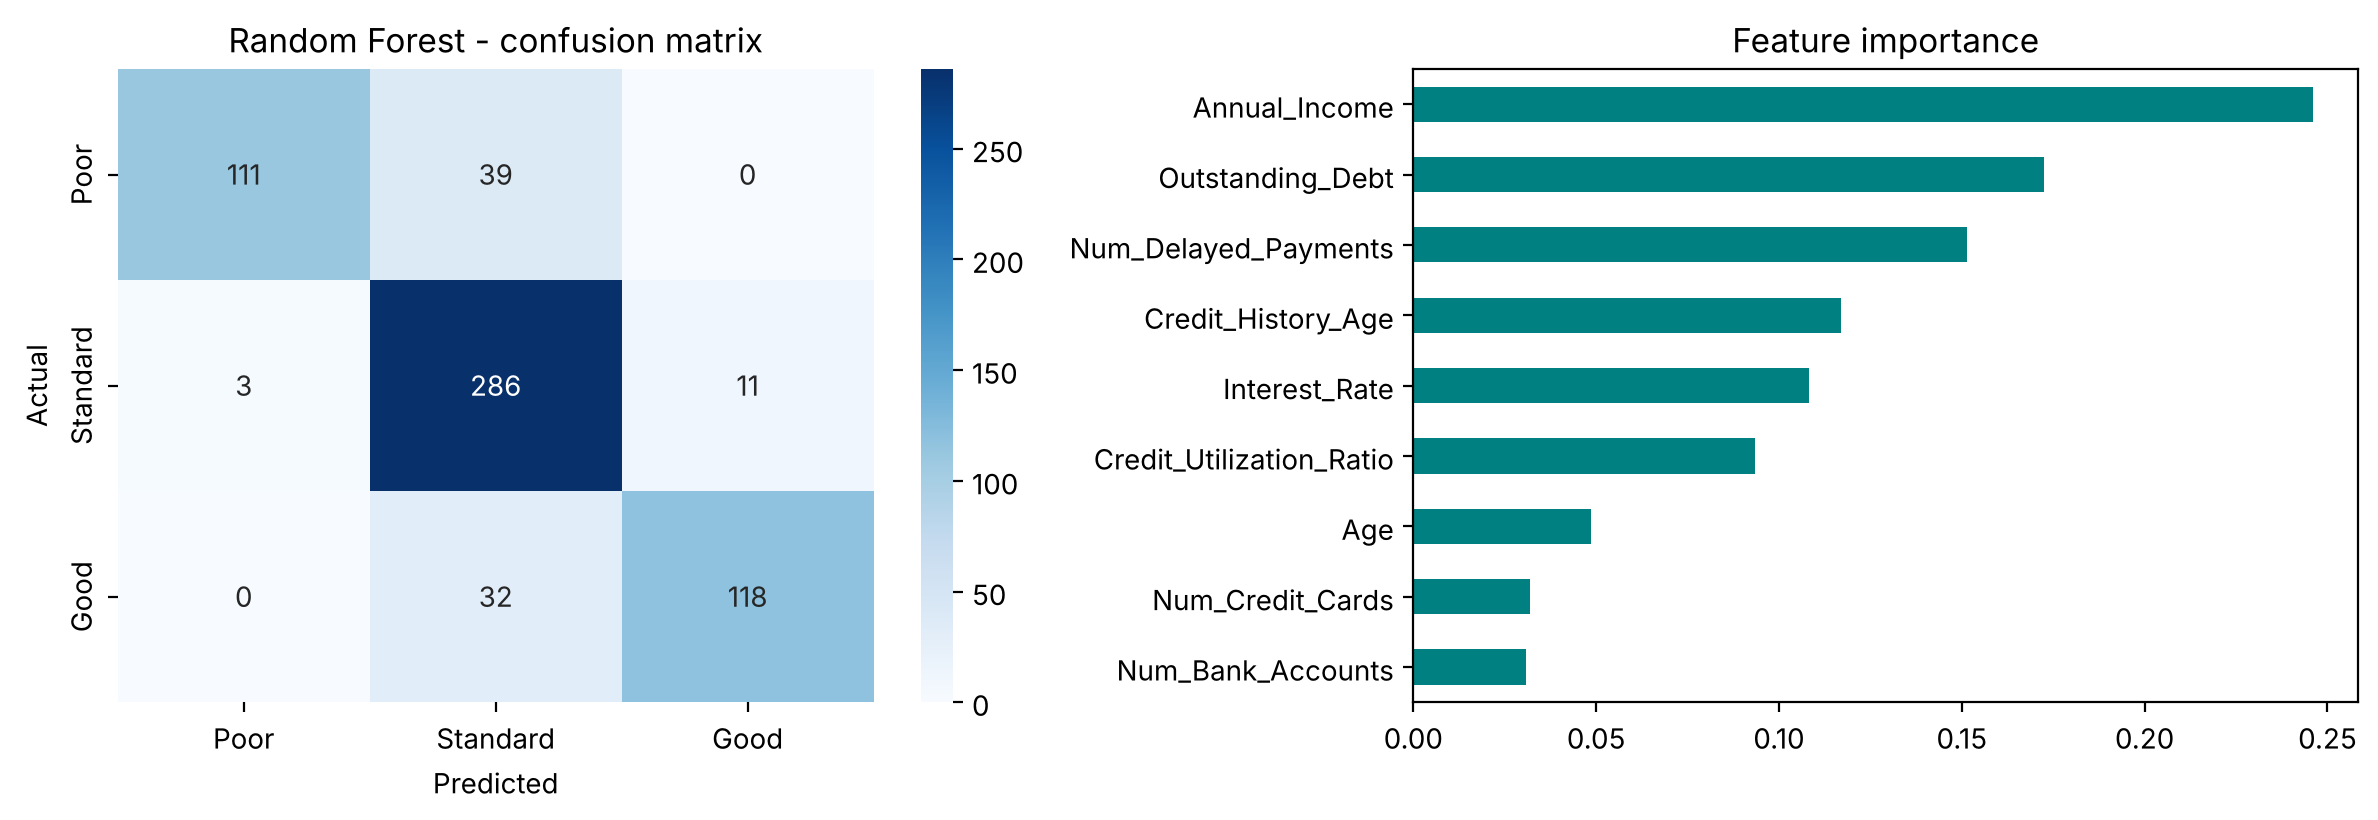

Top 5 features (Random Forest importance):
Annual_Income           0.246
Outstanding_Debt        0.173
Num_Delayed_Payments    0.151
Credit_History_Age      0.117
Interest_Rate           0.108
Predicted credit score for the new customer: Good


In [3]:
labels = ['Poor', 'Standard', 'Good']
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(confusion_matrix(y_test, rf_pred, labels=labels), annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels, ax=ax[0])
ax[0].set_title('Random Forest - confusion matrix'); ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(ax=ax[1], color='teal'); ax[1].set_title('Feature importance')
plt.tight_layout(); plt.show()
print('Top 5 features (Random Forest importance):')
print(imp.sort_values(ascending=False).head(5).round(3).to_string())

new_customer = pd.DataFrame([{
    'Age': 35, 'Annual_Income': 72000, 'Num_Bank_Accounts': 3, 'Num_Credit_Cards': 4,
    'Interest_Rate': 6, 'Num_Delayed_Payments': 1, 'Credit_Utilization_Ratio': 28.0,
    'Outstanding_Debt': 600.0, 'Credit_History_Age': 15}])
print('Predicted credit score for the new customer:', rf.predict(new_customer)[0])

## Result
Both models classify customers into Poor / Standard / Good. Logistic Regression (about 93 % accuracy) beats the Random Forest (about 86 %) here because the synthetic score is close to a linear function of the features. In the Random Forest, annual income, outstanding debt, number of delayed payments, credit-history age and interest rate are the most important features.